In [1]:
%pip install tensorflow gradio scipy pillow matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


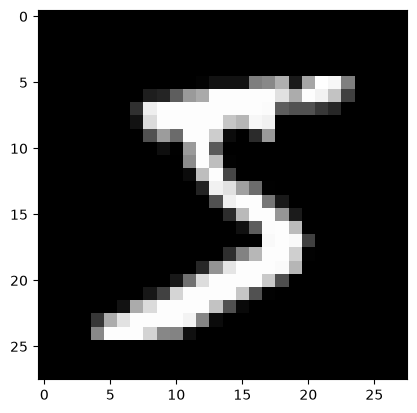

In [2]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.reshape(x_train.shape[0], 28*28)
x_test = x_test.reshape(x_test.shape[0], 28*28)

plt.imshow(x_train[0].reshape(28,28), cmap='gray')
plt.show()

In [3]:
In = tf.keras.layers.Input(shape=(784,))
Cp1 = tf.keras.layers.Dense(64, activation='relu')(In)
Cp2 = tf.keras.layers.Dense(16, activation='relu')(Cp1) #El relu quita los valores que sean menores a 0
Out = tf.keras.layers.Dense(10, activation='softmax')(Cp2) #El softmax de vuelve un vector con probabilidades de pertencer a una clase [ 0, 0, 0, 0, 0, 0, 0, 0.7, 0, 0, 0.3, 0] esto nos puedes mostrar la seguridad del model, aunque esta seguridad no asegura que el modelo sea confiable
Model = tf.keras.Model(inputs=In, outputs=Out)

In [4]:
Model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,450 (200.98 KB)

 Trainable params: 51,450 (200.98 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
Model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
Model.fit(x_train, y_train, epochs=30, batch_size=32)

Epoch 1/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.4863 - loss: 1.6969
Epoch 2/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.6780 - loss: 0.9430
Epoch 3/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7645 - loss: 0.6747
Epoch 4/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8840 - loss: 0.4257
Epoch 5/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9332 - loss: 0.2541
Epoch 6/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9458 - loss: 0.2026
Epoch 7/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9549 - loss: 0.1658
Epoch 8/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9609 - loss: 0.1413
Epoch 9/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9656 - loss: 0.1271
Epoch 10/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9680 - loss: 0.1166
Epoch 11/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9713 - loss: 0.1061
Epoch 12/30
1875/1875 ━━━━━━━━

In [6]:
!pip install -q gradio


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


In [7]:
import numpy as np
import gradio as gr
from PIL import Image
from scipy import ndimage


def preprocesar(imagen):
    """Convierte una foto/imagen de un dígito al formato de MNIST:
    28x28, fondo negro, trazo blanco, dígito en caja de 20x20 y centrado
    por centro de masa. Devuelve un array 28x28 con valores 0-255."""

    # Gradio puede entregar un dict (editor) o un array numpy
    if isinstance(imagen, dict):
        imagen = imagen.get("composite", imagen.get("background"))

    img = Image.fromarray(np.asarray(imagen).astype("uint8"))

    # Si tiene transparencia, ponerla sobre fondo blanco
    if img.mode in ("RGBA", "LA"):
        fondo = Image.new("RGB", img.size, (255, 255, 255))
        fondo.paste(img, mask=img.split()[-1])
        img = fondo

    arr = np.asarray(img.convert("L")).astype("float32")

    # Si el fondo es claro (hoja blanca), invertir: MNIST es trazo blanco sobre negro
    borde = np.concatenate([arr[0, :], arr[-1, :], arr[:, 0], arr[:, -1]])
    if np.median(borde) > 127:
        arr = 255 - arr

    # Estirar contraste a 0-255 y eliminar ruido débil
    arr = arr - arr.min()
    if arr.max() > 0:
        arr = arr / arr.max() * 255
    arr[arr < 40] = 0

    # Recortar al rectángulo que contiene el dígito
    ys, xs = np.where(arr > 0)
    if len(ys) == 0:
        return np.zeros((28, 28), dtype="uint8")
    arr = arr[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

    # Escalar para que el lado mayor mida 20 px (como en MNIST)
    h, w = arr.shape
    escala = 20.0 / max(h, w)
    nuevo_w, nuevo_h = max(1, int(round(w * escala))), max(1, int(round(h * escala)))
    arr = np.asarray(
        Image.fromarray(arr.astype("uint8")).resize((nuevo_w, nuevo_h), Image.LANCZOS)
    ).astype("float32")

    # Pegar en un lienzo 28x28
    lienzo = np.zeros((28, 28), dtype="float32")
    y0, x0 = (28 - nuevo_h) // 2, (28 - nuevo_w) // 2
    lienzo[y0:y0 + nuevo_h, x0:x0 + nuevo_w] = arr

    # Centrar por centro de masa (así están centrados los dígitos de MNIST)
    cy, cx = ndimage.center_of_mass(lienzo)
    lienzo = ndimage.shift(lienzo, (14 - cy, 14 - cx), order=1, mode="constant")

    return np.clip(lienzo, 0, 255).astype("uint8")


def predecir(imagen):
    if imagen is None:
        return None, None

    img28 = preprocesar(imagen)

    # OJO: el modelo se entrenó SIN dividir entre 255,
    # así que la entrada debe quedarse en el rango 0-255.
    entrada = img28.reshape(1, 784).astype("float32")
    probs = Model.predict(entrada, verbose=0)[0]

    confianzas = {str(i): float(probs[i]) for i in range(10)}
    return confianzas, img28


demo = gr.Interface(
    fn=predecir,
    inputs=gr.Image(
        label="Sube la imagen de tu número escrito a mano",
        sources=["upload", "webcam", "clipboard"],
        type="numpy",
    ),
    outputs=[
        gr.Label(num_top_classes=10, label="Predicción del modelo (probabilidad por clase)"),
        gr.Image(label="Lo que realmente ve el modelo (28x28)", image_mode="L"),
    ],
    title="Reconocedor de dígitos escritos a mano (MNIST)",
    description=(
        "Red densa 784 → 64 → 16 → 10. Sube una foto de un solo dígito, "
        "preferiblemente con trazo grueso y oscuro sobre fondo claro."
    ),
    flagging_mode="never",
)

demo.launch(debug=False)

c:\Users\gomes\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
